# EWC and replay vs the baseline models: ANN vs SNN

This notebook compares continual-learning mechanisms against the baseline models (`baseline.ipynb`), for both an ANN and an SNN:

- **Task-incremental:** Baseline vs EWC.
- **Class-incremental:** Baseline vs EWC vs Replay vs EWC + Replay.

The sections below give the context needed to read the graphs. They cover the problem, the setup, how each mechanism works, the hyperparameters, the conditions that were run, and why replay had to be added for the class-incremental scenario.

## Background: catastrophic forgetting
A neural network trained on one task and then on another usually loses most of what it knew about the first. Training on the new task changes the same weights the old task relied on, with nothing to stop it. This is **catastrophic forgetting**. Continual-learning mechanisms try to let a network learn tasks one after another while keeping the old ones.

## Experimental setup
**Benchmark: Split CIFAR-10.** CIFAR-10 is split into 5 tasks of 2 classes, always trained in this order: T1 airplane/automobile, T2 bird/cat, T3 deer/dog, T4 frog/horse, T5 ship/truck. Each task is trained to completion before the next begins, and earlier tasks' training data is not available again (except through replay, below).

**Two scenarios:**
- **Task-incremental:** at test time the model is told which task an image belongs to and only picks between that task's 2 classes. The network has a shared body plus one 2-class output head per task. Chance = 50%.
- **Class-incremental:** the model isn't told the task and must pick among all 10 classes with one shared output layer. This is the harder, more realistic setting. Chance = 10%.

**Models:**
- **ANN:** fully connected, 3072 → 512 → 256 → output, ReLU activations.
- **SNN:** the same layers with leaky integrate-and-fire (LIF) spiking neurons instead of ReLU (SpikingJelly, sigmoid surrogate gradient). The image is presented unchanged at every time step (direct encoding), and the output is averaged over T time steps.

Both models use the same architecture, optimiser and data, so differences come from the neuron type.

## The mechanisms

### Baseline (no mechanism)
The model is trained on each task in turn with ordinary cross-entropy loss and nothing protecting old tasks. In the continual-learning literature this is also called *fine-tuning*. It shows how much is forgotten when nothing is done.

### Elastic Weight Consolidation (EWC)
*Kirkpatrick et al., 2017.* A **regularisation** method: it doesn't store any old data. Instead, it slows down changes to the weights that mattered most for earlier tasks.

1. After finishing a task, EWC estimates how important each weight was for that task using the **Fisher information**: the average squared gradient of the loss with respect to that weight. A large value means changing that weight would hurt the task a lot.
2. It saves a copy of the weights as they were at that point (θ*).
3. While training later tasks, it adds a penalty to the loss:

   loss = cross-entropy on the new task + ½ · λ · Σ F · (θ − θ*)²

   Each weight is pulled back towards its old value, with a strength set by its importance F. Unimportant weights stay free to learn the new task.

One importance estimate and weight copy is stored per finished task, and their penalties are added together.

### Experience replay
A **rehearsal** method. After each task, a small random sample of its training images (200 here) is kept in a memory buffer. While training a new task, each training step also includes one batch from every old task's buffer, and all the losses are averaged with equal weight. The network keeps practising old tasks alongside the new one. Stored images still get fresh random augmentation each time they're replayed.

Keeping a small buffer (200 of 10,000 images per task, i.e. 2%) is a standard continual-learning method. Keeping *all* old data would be **joint training**: an upper bound to compare against, not continual learning.

### EWC + Replay
Both together: the replay losses are averaged with the new-task loss, and the EWC penalty is added on top.

### Multi-Synaptic Cooperation Network (MSCN): not in this notebook yet
*Li et al., ICLR 2026, implemented in `multi_synaptic/`.* An **architectural** method with three parts:
1. **Task-specific sub-networks:** each weight has a learnable relevance score, and each task uses only the top 50% of weights in each layer (the *mask density*). After a task is finished, the weights it used are **frozen**. Later tasks can reuse them but can't change them, so old tasks can't be forgotten.
2. **Parallel synapses (P):** up to 3 weights per connection, each with its own response. In the ANN these are linear, ReLU and absolute value. In the SNN they are spike filters with different decay time constants (1–10 time steps), so the connection integrates input over different timescales.
3. **Plasticity modulation:** a running trace of recent activity scales how much each synapse is updated. Settings come from the papers MSCN builds on: θ_max = 1.2, e_inv = 0.5, trace decay τ = 10 batches.

MSCN needs the task ID to pick the right mask, so it only applies to the task-incremental scenario. Its results will be added once those runs are complete.

## Hyperparameters

**Shared by every run**

| Setting | Value |
|---|---|
| Optimiser | Adam |
| Learning rate | 1e-3 |
| Batch size | 128 |
| Augmentation | random crop (padding 4) and horizontal flip |
| Seeds | 42, 123, 456, 789, 1011 |
| SNN neuron | LIF, sigmoid surrogate gradient, direct input encoding |

**EWC**

| Setting | Value | Meaning |
|---|---|---|
| λ (lambda) | 100 | How strongly old weights are held in place. Too low and EWC has no effect; too high and new tasks can't be learned. |
| Fisher method | empirical | Importance is computed using the true labels. |
| Fisher samples | 1,024 | Training images used to estimate each task's weight importance. |

**Replay**

| Setting | Value | Meaning |
|---|---|---|
| Images per old task | 200 | 2% of each task's 10,000 training images. |
| Replay batch | 128 per old task, each step | Taken from the buffer and averaged with the new-task loss with equal weight. |

## Conditions run

| Condition | Epochs per task | SNN time steps T |
|---|---|---|
| 1 | 1 | 2 |
| 2 | 2 | 4 |
| 3 | 5 | 7 |

- **Epochs** set how long each task is trained. More epochs help the current task but can push old knowledge further away.
- **T** is how many time steps the SNN runs per image. More steps give the spikes more time to carry information but cost more compute. T doesn't affect the ANN.
- Epochs and T were changed together, so their effects can't be separated.

**Runs available**

| Scenario | Method | Conditions | Seeds |
|---|---|---|---|
| Task-incremental | Baseline, EWC | 1, 2, 3 | 5 |
| Class-incremental | Baseline, EWC, Replay, EWC + Replay | 1, 2, 3 | 5 |

Every method has all 3 conditions with the same 5 seeds. Class-incremental EWC was run in three parts (conditions 1–2 with seeds 42/123/456, then seeds 789/1011, then condition 3), so the notebook merges those files by condition.

Graphs that show a single condition (sections 2, 3, 5 and 6) use **condition 3** (5 epochs, T = 7), the longest training and the setting where the methods differ most. To view another condition, change `KEY` in the loading cell to `(1, 2)` or `(2, 4)` and re-run.

## Why EWC works for task-incremental but not class-incremental
This was the main problem encountered during the experiments, and it explains why replay was added.

**Task-incremental:** each task has its own output head, so learning a new task can't overwrite an old task's output layer. Forgetting only comes from the shared body drifting. That's exactly what EWC targets, and it works: forgetting falls and accuracy rises.

**Class-incremental:** all 10 classes share one output layer. When the model trains on task 2 (bird/cat), every training label is bird or cat, so the quickest way to lower the loss is to push the outputs for airplane and automobile down. After a few batches the model never predicts old classes again, and task 1's accuracy falls to **0%**. EWC can't stop this. Its penalty protects weights that were important for recognising old classes, but the damage is a bias in the output layer towards whichever classes are currently being trained. Keeping old weights in place doesn't make the model choose old classes.

**Evidence:** a separate λ sweep (`raw_results/ewc_lambda_sweep_5epoch.json`, ANN, 1 seed, 2 tasks) tried λ = 10, 100 and 1000. In every case task 1's accuracy fell from 86.5% to 0% after task 2. Turning EWC up didn't help. This matches the literature: van de Ven et al. (2022), *Three types of incremental learning*, found regularisation methods like EWC fail in class-incremental learning.

**The fix: replay.** Mixing a few stored images of old classes into each training step means the model sees all the classes it has learned and has to keep distinguishing them. That directly counteracts the bias towards new classes. EWC was kept alongside replay to test whether the two together do better than replay alone.

## Metrics
- **Final average accuracy:** mean accuracy over all 5 tasks after the last task is trained.
- **Forgetting:** for each of tasks 1–4, the accuracy right after it was trained minus its accuracy at the end, averaged over those tasks. Lower is better.
- **Accuracy matrix:** every task's accuracy after every stage of training.

Error bars and shaded bands are ±1 standard deviation across seeds. Every figure is also saved to `figures/`.

## Setup
Imports, plot style and helper functions that read the result files and compute the metrics above.

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

RESULTS = Path.cwd().parent / "raw_important_results"   # notebook lives in "visualised_results/"
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#9a998f", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})
MODEL_COLORS = {"ann": "#2a78d6", "snn": "#eb6834"}
MODEL_NAMES = {"ann": "ANN", "snn": "SNN"}
CHANCE = {"task": 0.5, "class": 0.1}
TASK_NAMES = ["T1 plane/car", "T2 bird/cat", "T3 deer/dog", "T4 frog/horse", "T5 ship/truck"]


def load(rel_path):
    """List of conditions; each has epochs, snn_time_steps and per-model seed runs."""
    with open(RESULTS / rel_path) as f:
        return json.load(f)["conditions"]


def cond_label(c):
    return f"{c['epochs']} ep, T={c['snn_time_steps']}"


def final_acc(runs):
    """Mean and std (over seeds) of final average accuracy across all 5 tasks."""
    a = np.array([r["final_accuracy"] for r in runs])
    return a.mean(), a.std()


def curve(runs):
    """seeds x tasks: average accuracy on tasks seen so far, after each task."""
    return np.array([[t["average_accuracy"] for t in r["tasks"]] for r in runs])


def acc_matrix(runs):
    """M[i, j] = accuracy on task j after training task i (mean over seeds)."""
    n = len(runs[0]["tasks"])
    M = np.full((len(runs), n, n), np.nan)
    for s, r in enumerate(runs):
        for i, t in enumerate(r["tasks"]):
            M[s, i, : len(t["task_accuracies"])] = t["task_accuracies"]
    return M.mean(axis=0)


def forgetting(runs):
    """Mean and std (over seeds) of average forgetting of tasks 1-4 at the end."""
    f = np.array([np.mean(list(r["tasks"][-1]["forgetting"].values())) for r in runs])
    return f.mean(), f.std()


def train_time(runs):
    t = np.array([r["total_training_time_seconds"] for r in runs]) / 60
    return t.mean(), t.std()


def grouped_bars(ax, groups, series, colors, labels, fmt="{:.0%}", width=0.8):
    """groups: x tick labels. series: list of (means, stds) per series, NaN = missing."""
    n = len(series)
    w = width / n
    x = np.arange(len(groups))
    for k, (means, stds) in enumerate(series):
        pos = x - width / 2 + w * (k + 0.5)
        bars = ax.bar(pos, means, w - 0.03, yerr=stds, color=colors[k], label=labels[k],
                      error_kw={"elinewidth": 1, "capsize": 2, "ecolor": "#52514e"})
        for b, m, sd in zip(bars, means, stds):
            cx = b.get_x() + b.get_width() / 2
            if np.isnan(m):
                ax.annotate("not run", (cx, 0), xytext=(0, 3), textcoords="offset points", ha="center",
                            va="bottom", rotation=90, fontsize=7, color="#9a998f")
            elif fmt:
                ax.annotate(fmt.format(m), (cx, m + (0 if np.isnan(sd) else sd)), xytext=(0, 2),
                            textcoords="offset points", ha="center", va="bottom",
                            fontsize=8, color="#0b0b0b")
    ax.set_xticks(x, groups)

## Load results and summary table
Loads each method's result file and prints every number behind the charts: mean ± std across seeds, number of seeds, and training time per seed in minutes.

In [2]:
def merge(*paths):
    """Combine result files that hold different conditions or seeds of the same experiment."""
    merged = {}
    for path in paths:
        for c in load(path):
            key = (c["epochs"], c["snn_time_steps"])
            if key not in merged:
                merged[key] = {**c, "ann": {"runs": []}, "snn": {"runs": []}}
            for m in ("ann", "snn"):
                seeds = {r["seed"] for r in merged[key][m]["runs"]}
                merged[key][m]["runs"] += [r for r in c[m]["runs"] if r["seed"] not in seeds]
    return [merged[k] for k in sorted(merged)]


METHOD_COLORS = {"Baseline": "#2a78d6", "EWC": "#eb6834", "Replay": "#1baf7a", "EWC + Replay": "#eda100"}
SCENARIO_TITLE = {"task": "Task-incremental", "class": "Class-incremental"}

data = {
    "task": {
        "Baseline": load("baseline/task_cond123.json"),
        "EWC": load("ewc/task_ewc_cond123_secondrun.json"),
    },
    "class": {
        "Baseline": load("baseline/class_1_2_5epochbaselinerun.json"),
        "EWC": merge("ewc/class_ewc_cond12.json",             # conditions 1-2, seeds 42/123/456
                     "ewc/class_ewc_cond12_last2seeds.json",  # conditions 1-2, seeds 789/1011
                     "ewc/class_ewc_cond3.json"),             # condition 3, all 5 seeds
        "Replay": load("ewc/class_replay_cond123.json"),
        "EWC + Replay": load("ewc/class_ewc_replay_cond123.json"),
    },
}
# Conditions keyed by (epochs, T) so methods with missing conditions line up as gaps.
CONDS = [(1, 2), (2, 4), (5, 7)]
COND_LABELS = [f"{e} ep, T={t}" for e, t in CONDS]
KEY = (5, 7)  # condition used by the single-condition graphs (sections 2, 3, 5, 6)


def by_cond(conds, key):
    return {(c["epochs"], c["snn_time_steps"]): c for c in conds}.get(key)


def per_cond(conds, model, fn):
    """(means, stds) over CONDS; NaN where the condition was not run."""
    out = [fn(c[model]["runs"]) if (c := by_cond(conds, k)) else (np.nan, np.nan) for k in CONDS]
    return tuple(np.array(out).T)


print(f"{'scenario':<8} {'method':<13} {'condition':<12} {'model':<5} {'seeds':>5} {'final acc':>14} {'forgetting':>14} {'time/seed':>11}")
for sc, methods in data.items():
    for name, conds in methods.items():
        for c in conds:
            for m in ("ann", "snn"):
                runs = c[m]["runs"]
                a, as_ = final_acc(runs); f, fs = forgetting(runs); t, _ = train_time(runs)
                print(f"{sc:<8} {name:<13} {cond_label(c):<12} {MODEL_NAMES[m]:<5} {len(runs):>5} "
                      f"{a:>8.1%} ±{as_:.1%} {f:>8.1%} ±{fs:.1%} {t:>8.1f} min")

scenario method        condition    model seeds      final acc     forgetting   time/seed
task     Baseline      1 ep, T=2    ANN       5    69.2% ±3.0%    10.5% ±3.1%      0.4 min
task     Baseline      1 ep, T=2    SNN       5    68.5% ±0.6%     8.5% ±1.3%      0.7 min
task     Baseline      2 ep, T=4    ANN       5    69.6% ±1.4%    11.8% ±1.9%      0.8 min
task     Baseline      2 ep, T=4    SNN       5    66.5% ±2.4%    11.9% ±2.9%      4.0 min
task     Baseline      5 ep, T=7    ANN       5    69.9% ±2.0%    13.4% ±2.4%      4.1 min
task     Baseline      5 ep, T=7    SNN       5    66.2% ±2.8%    14.8% ±3.9%     25.1 min
task     EWC           1 ep, T=2    ANN       5    74.7% ±1.1%     4.0% ±0.8%      0.3 min
task     EWC           1 ep, T=2    SNN       5    71.6% ±1.4%     4.8% ±1.0%      0.5 min
task     EWC           2 ep, T=4    ANN       5    76.2% ±0.8%     3.8% ±1.3%      0.8 min
task     EWC           2 ep, T=4    SNN       5    74.4% ±0.9%     2.7% ±0.5%      1.5 min


## 1. Final average accuracy by method
**What it shows:** accuracy over all 5 tasks at the end of training, for every method and condition. Top row: task-incremental. Bottom row: class-incremental. Left: ANN. Right: SNN. The dashed line is chance level.

**How to read it:** compare each coloured bar with the blue Baseline bar in the same group. The rows have different y-axis ranges because the scenarios aren't comparable.

**What to look for:**
- **Task-incremental:** EWC (orange) should sit above Baseline in every condition.
- **Class-incremental:** EWC alone barely moves from Baseline, while Replay (green) and EWC + Replay (yellow) give a large jump.
- **Effect of conditions:** whether training longer (condition 3) helps or hurts each method. Longer training learns each task better but can also push old knowledge further away.

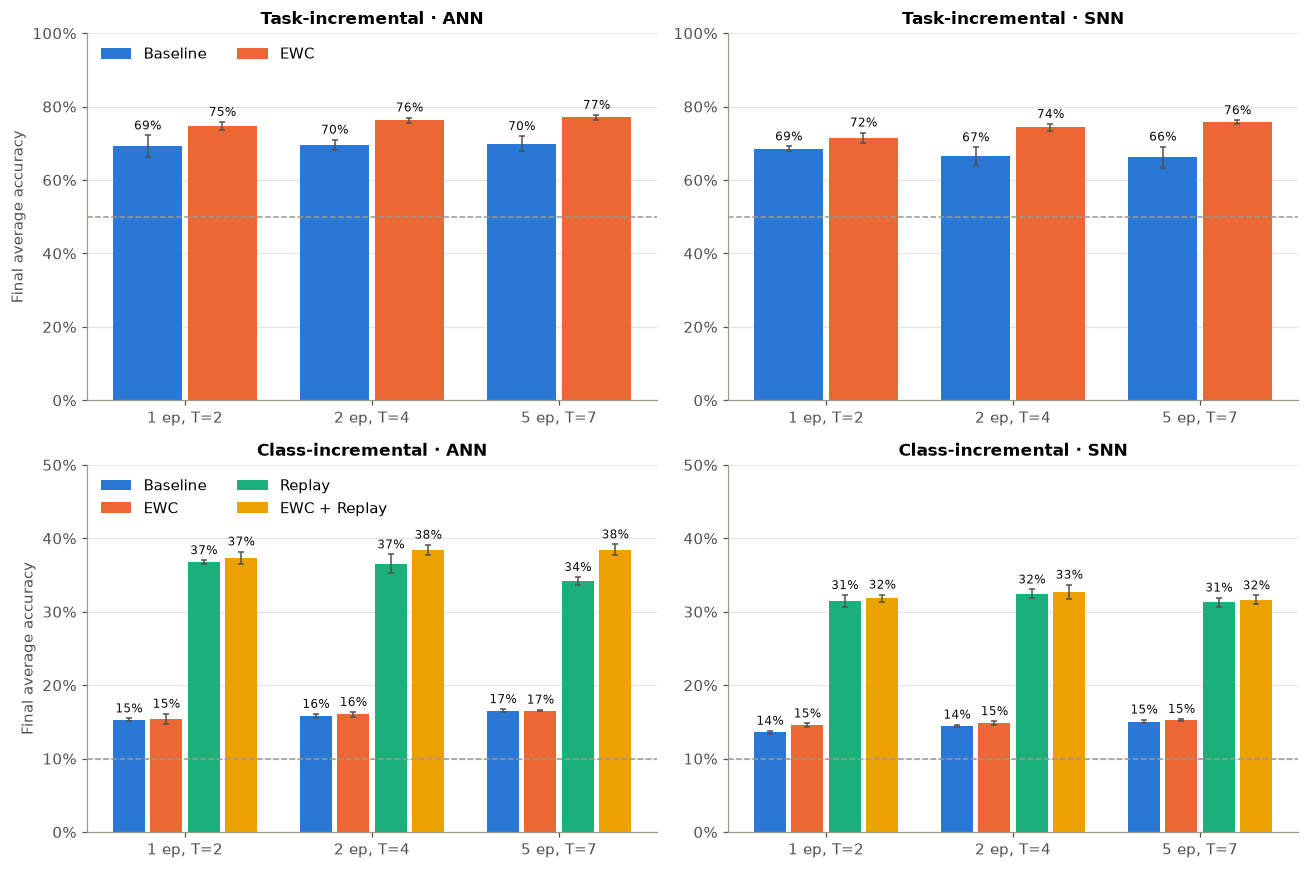

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (sc, methods) in enumerate(data.items()):
    for col, m in enumerate(("ann", "snn")):
        ax = axes[row, col]
        names = list(methods)
        grouped_bars(ax, COND_LABELS, [per_cond(methods[n], m, final_acc) for n in names],
                     [METHOD_COLORS[n] for n in names], names)
        ax.axhline(CHANCE[sc], ls="--", lw=1, color="#9a998f")
        ax.set_title(f"{SCENARIO_TITLE[sc]} · {MODEL_NAMES[m]}")
        ax.set_ylim(0, 1 if sc == "task" else 0.5)
        ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
        if col == 0:
            ax.set_ylabel("Final average accuracy")
            ax.legend(loc="upper left", ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "ewc_final_accuracy.png")
plt.show()

## 2. ANN vs SNN under each method
**What it shows:** the same final accuracies as graph 1, rearranged so the ANN (blue) and SNN (orange) sit side by side for each method. Uses condition 3 (5 epochs, T = 7).

**How to read it:** the gap between each pair of bars is the cost or benefit of using spiking neurons with that method.

**What to look for:**
- **The size of the gap:** whether it stays roughly constant across methods, which would mean the mechanisms help both networks equally.
- **Changes in the gap:** whether it shrinks or grows under a particular mechanism, which would mean the SNN benefits more or less from it.

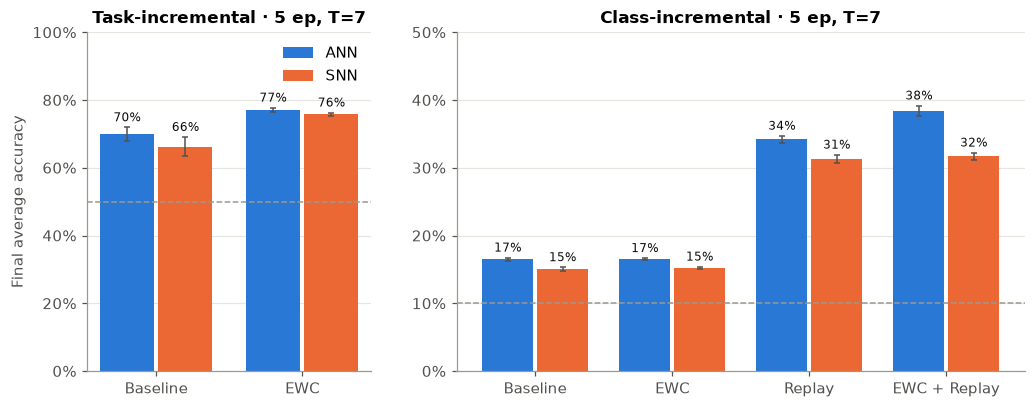

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [2, 4]})
for ax, (sc, methods) in zip(axes, data.items()):
    names = list(methods)
    series = [tuple(np.array([final_acc(by_cond(methods[n], KEY)[m]["runs"]) for n in names]).T)
              for m in ("ann", "snn")]
    grouped_bars(ax, names, series, [MODEL_COLORS["ann"], MODEL_COLORS["snn"]], ["ANN", "SNN"])
    ax.axhline(CHANCE[sc], ls="--", lw=1, color="#9a998f")
    ax.set_title(f"{SCENARIO_TITLE[sc]} · {KEY[0]} ep, T={KEY[1]}")
    ax.set_ylim(0, 1 if sc == "task" else 0.5)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
axes[0].set_ylabel("Final average accuracy")
axes[0].legend(loc="upper right")
fig.savefig(FIG_DIR / "ewc_ann_vs_snn.png")
plt.show()

## 3. Accuracy as tasks are added
**What it shows:** after each task is trained (x-axis), the average accuracy over all tasks seen so far, one line per method (condition 3). The shaded band is ±1 std across seeds.

**How to read it:** every method starts at the same point because task 1 is trained identically (no mechanism has anything to protect yet). The lines separate from task 2 onwards, when the mechanisms start working. A flatter line means less forgetting.

**What to look for:**
- **Class-incremental:** Baseline and EWC fall almost on top of each other. That's the visual version of EWC failing in this scenario.
- **Class-incremental with replay:** Replay and EWC + Replay fall much more slowly.
- **Task-incremental:** EWC stays above Baseline from task 2 onwards.

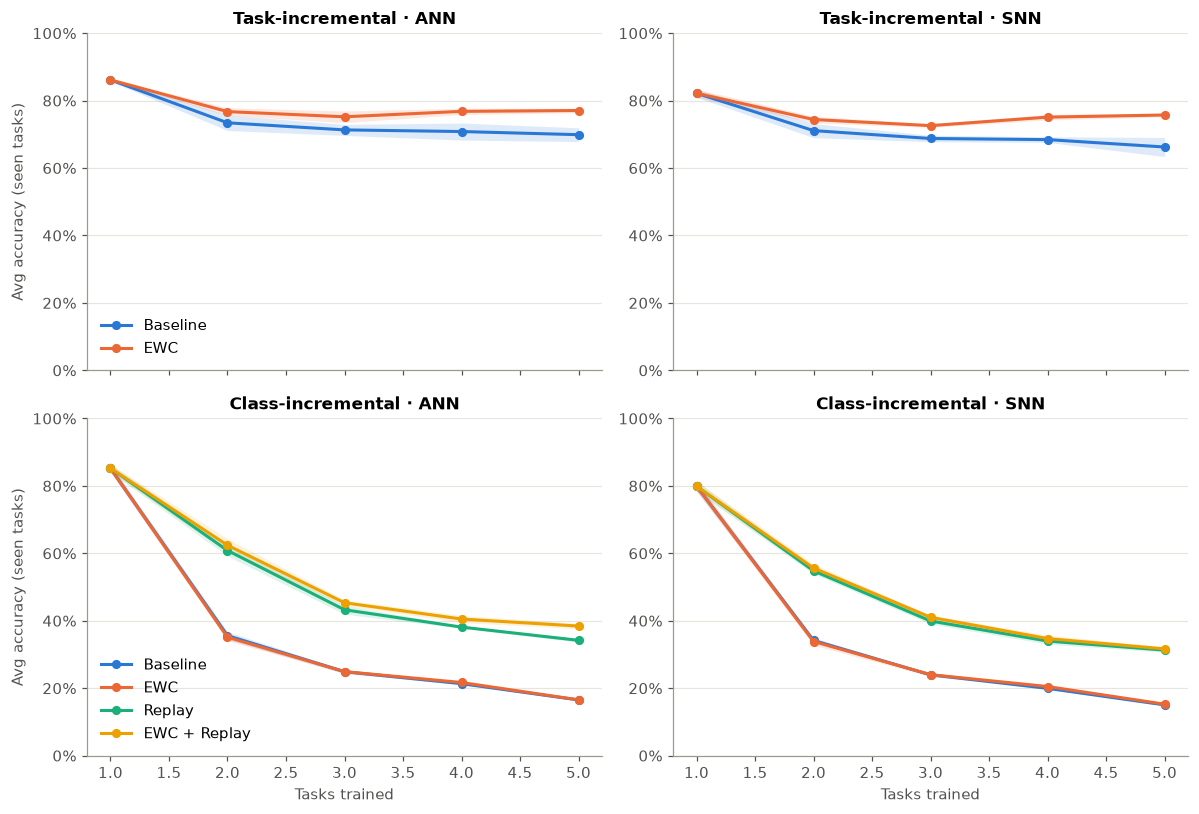

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True)
x = np.arange(1, 6)
for row, (sc, methods) in enumerate(data.items()):
    for col, m in enumerate(("ann", "snn")):
        ax = axes[row, col]
        for name, conds in methods.items():
            cv = curve(by_cond(conds, KEY)[m]["runs"])
            mu, sd = cv.mean(0), cv.std(0)
            ax.plot(x, mu, "-o", lw=2, ms=5, color=METHOD_COLORS[name], label=name)
            ax.fill_between(x, mu - sd, mu + sd, color=METHOD_COLORS[name], alpha=0.15, lw=0)
        ax.set_title(f"{SCENARIO_TITLE[sc]} · {MODEL_NAMES[m]}")
        ax.set_ylim(0, 1)
        ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
        if col == 0:
            ax.set_ylabel("Avg accuracy (seen tasks)")
            ax.legend(loc="lower left")
        if row == 1:
            ax.set_xlabel("Tasks trained")
fig.tight_layout()
fig.savefig(FIG_DIR / "ewc_accuracy_curves.png")
plt.show()

## 4. Forgetting by method
**What it shows:** how much accuracy tasks 1–4 lost by the end of training, averaged over those tasks, for each method and condition.

**How to read it:** **lower is better.** This isolates forgetting from how well tasks were learned in the first place. A method could have high final accuracy simply because it learns each task well, and this chart separates that out.

**What to look for:**
- **Task-incremental:** EWC should cut forgetting to a fraction of Baseline's.
- **Class-incremental:** Baseline and EWC lose almost everything, while replay cuts forgetting sharply.
- **EWC + Replay vs Replay:** whether adding EWC on top of replay reduces forgetting further, and whether that differs between the ANN and the SNN.

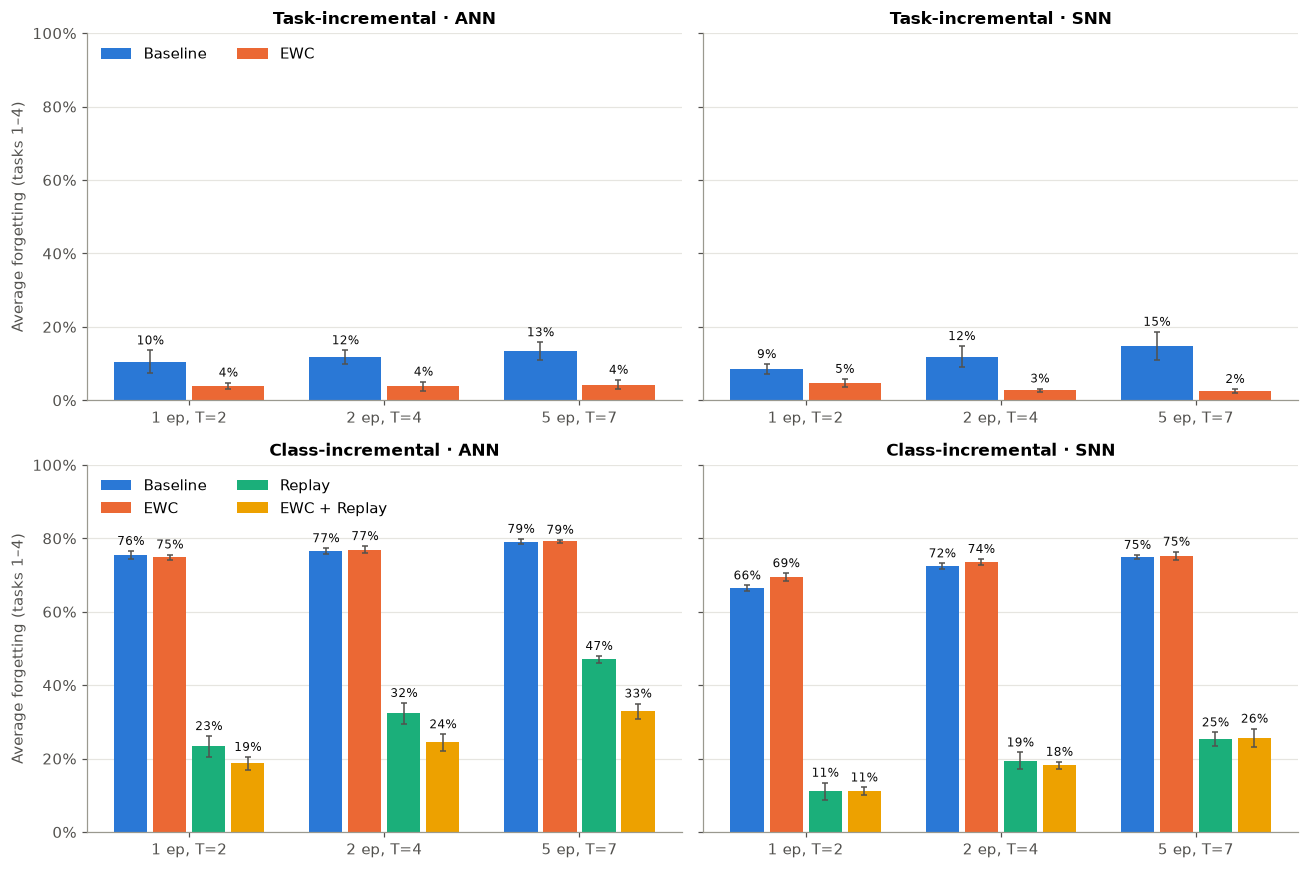

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for row, (sc, methods) in enumerate(data.items()):
    for col, m in enumerate(("ann", "snn")):
        ax = axes[row, col]
        names = list(methods)
        grouped_bars(ax, COND_LABELS, [per_cond(methods[n], m, forgetting) for n in names],
                     [METHOD_COLORS[n] for n in names], names)
        ax.set_title(f"{SCENARIO_TITLE[sc]} · {MODEL_NAMES[m]}")
        ax.set_ylim(0, 1)
        ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
        if col == 0:
            ax.set_ylabel("Average forgetting (tasks 1–4)")
            ax.legend(loc="upper left", ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "ewc_forgetting.png")
plt.show()

## 5. Accuracy matrices
**What it shows:** the full history of every task's accuracy throughout training, one matrix per method and network (condition 3, mean over seeds).

**How to read it:**
- Each **row** is a moment in training: just after training task 1, 2, …, 5.
- Each **column** is one task's test accuracy.
- The **diagonal** is how well each task was learned when it was the current task.
- **Reading down a column** follows one task over time. Paler cells further down mean it's being forgotten.
- The upper-right triangle is empty because those tasks haven't been trained yet.

The cell below defines the plotting function. The two cells after it draw one figure per scenario.

In [7]:
def plot_matrices(sc):
    names = list(data[sc])
    fig, axes = plt.subplots(2, len(names), figsize=(4 * len(names) + 1, 8), squeeze=False)
    for row, m in enumerate(("ann", "snn")):
        for col, name in enumerate(names):
            ax = axes[row, col]
            M = acc_matrix(by_cond(data[sc][name], KEY)[m]["runs"])
            im = ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
            for i in range(5):
                for j in range(i + 1):
                    ax.text(j, i, f"{M[i, j]:.0%}", ha="center", va="center", fontsize=8,
                            color="white" if M[i, j] > 0.6 else "#0b0b0b")
            ax.set_xticks(range(5), [f"T{j+1}" for j in range(5)])
            ax.set_yticks(range(5), [f"T{i+1}" for i in range(5)] if col == 0 else [])
            if col == 0:
                ax.set_ylabel("After training task")
            ax.set_xlabel("Accuracy on task")
            ax.grid(False)
            ax.set_title(f"{name} · {MODEL_NAMES[m]}")
    fig.suptitle(SCENARIO_TITLE[sc], fontweight="bold")
    fig.colorbar(im, ax=axes, shrink=0.6, label="Accuracy on task",
                 format=plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
    fig.savefig(FIG_DIR / f"ewc_{sc}_accuracy_matrix.png")
    plt.show()

### 5a. Task-incremental
**What to look for:**
- **Columns stay darker with EWC:** old tasks stay closer to the accuracy they had when first learned.
- **Diagonals look the same with and without EWC:** EWC protects old tasks without making new ones harder to learn.
- **Recovery:** some old tasks partly come back in later rows, because later tasks can rebuild features that earlier ones relied on.

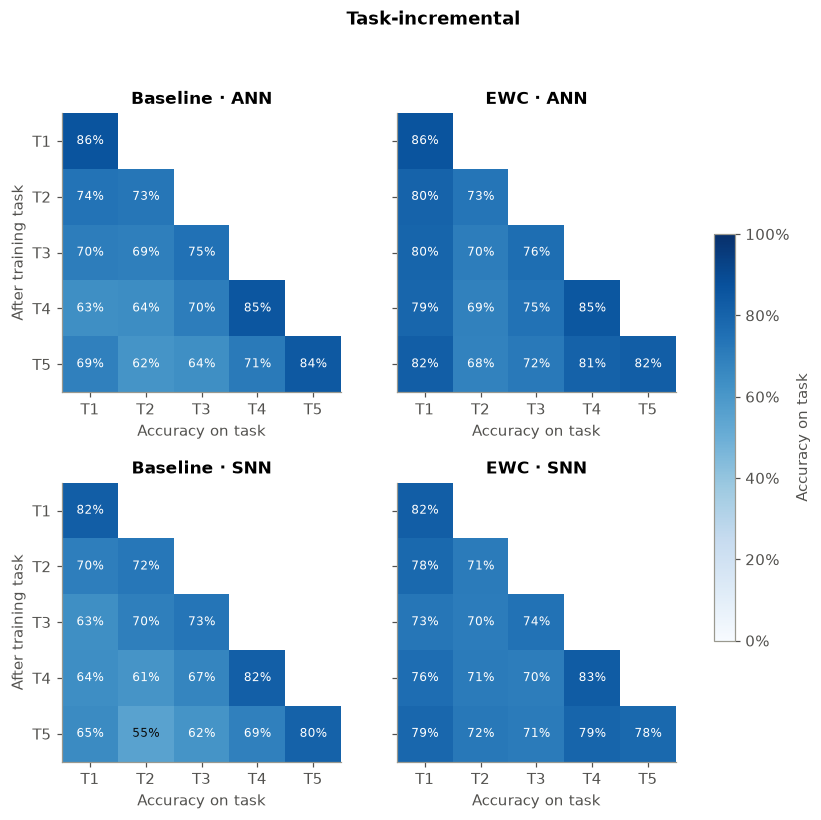

In [8]:
plot_matrices("task")

### 5b. Class-incremental
**What to look for:**
- **Baseline and EWC:** every cell left of the diagonal is 0%. Each new task wipes out the old ones immediately, which is the output-layer bias explained above.
- **Replay and EWC + Replay:** old tasks stay alive, but they fade over time, and the diagonal is lower. Sharing training with old tasks makes the new task harder to learn.
- **Hardest tasks:** visually similar pairs (T2 bird/cat, T3 deer/dog) are kept worst.

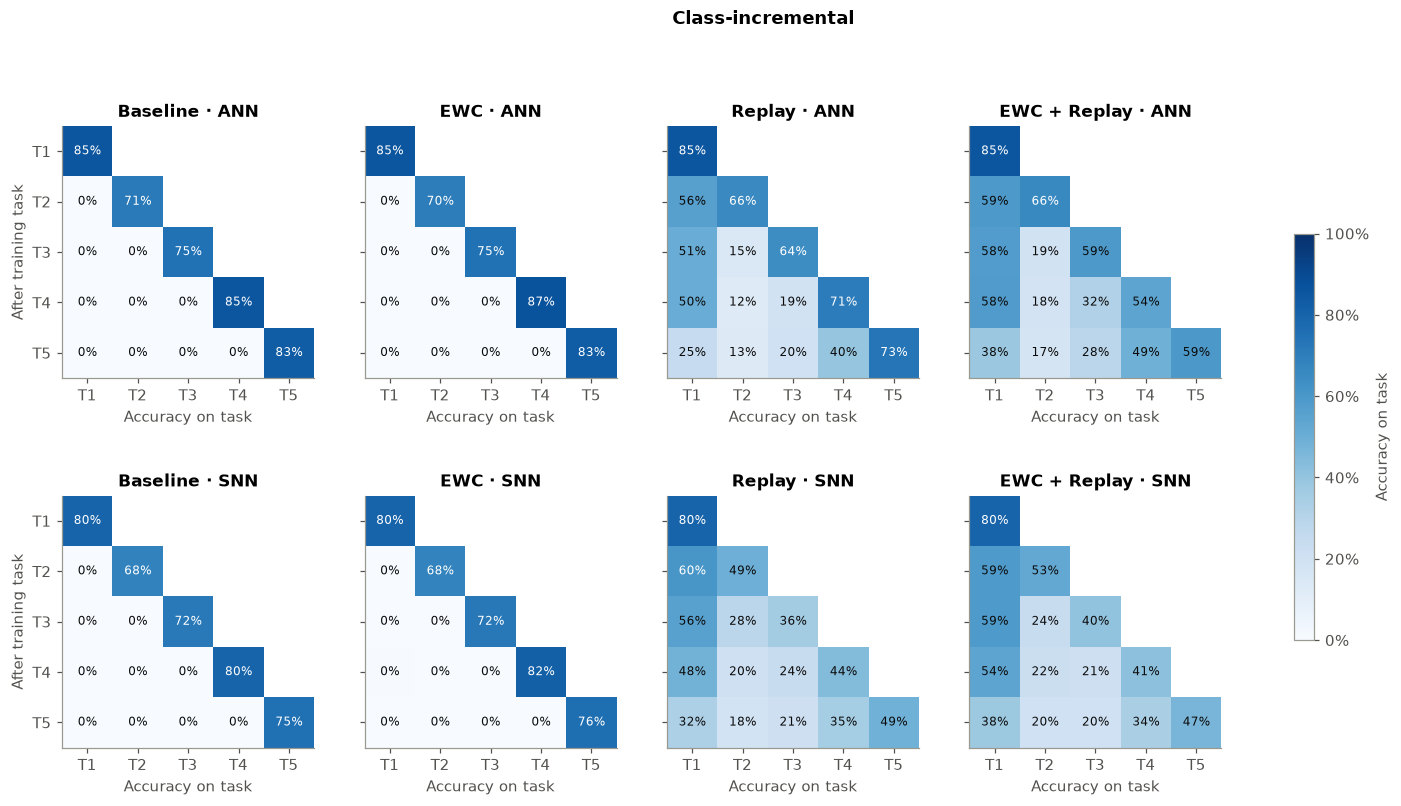

In [9]:
plot_matrices("class")

## 6. Final accuracy per task
**What it shows:** each task's accuracy at the very end of training, for each method (condition 3). This is the bottom row of the accuracy matrices, shown as bars.

**How to read it:** in class-incremental, the Baseline and EWC bars for T1–T4 are missing because their accuracy is 0%.

**What to look for:**
- **Task-incremental:** EWC lifts old tasks (T1–T4) most, while the most recent task (T5) is about the same either way.
- **Class-incremental:** replay spreads accuracy across all 5 tasks instead of concentrating it on T5, at the cost of lower T5 accuracy. That trade-off between stability (keeping old tasks) and plasticity (learning new ones) is central to continual learning.

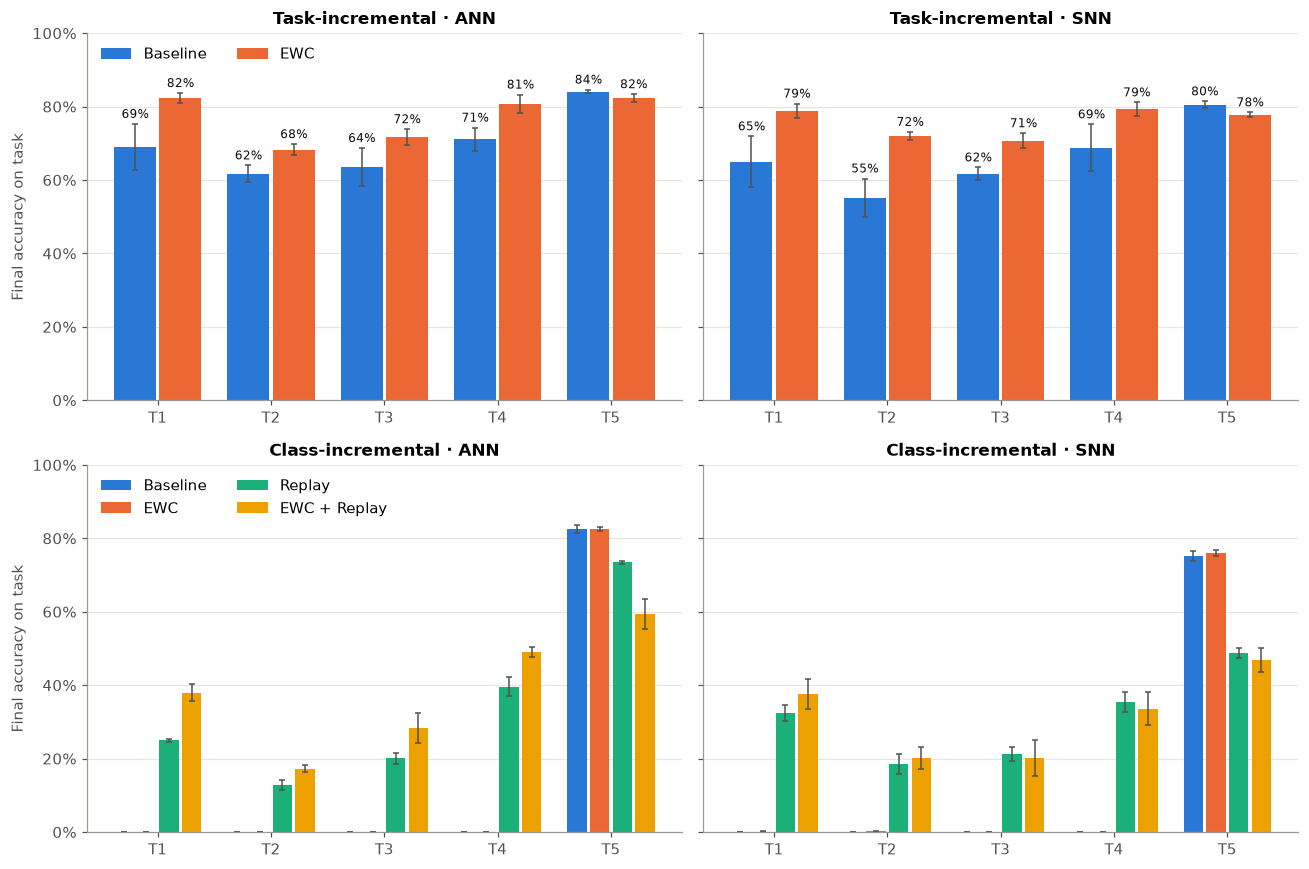

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for row, (sc, methods) in enumerate(data.items()):
    for col, m in enumerate(("ann", "snn")):
        ax = axes[row, col]
        names = list(methods)
        series = []
        for n in names:
            accs = np.array([r["tasks"][-1]["task_accuracies"] for r in by_cond(methods[n], KEY)[m]["runs"]])
            series.append((accs.mean(0), accs.std(0)))
        grouped_bars(ax, [t.split()[0] for t in TASK_NAMES], series,
                     [METHOD_COLORS[n] for n in names], names, fmt="{:.0%}" if len(names) < 4 else None)
        ax.set_title(f"{SCENARIO_TITLE[sc]} · {MODEL_NAMES[m]}")
        ax.set_ylim(0, 1)
        ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
        if col == 0:
            ax.set_ylabel("Final accuracy on task")
            ax.legend(loc="upper left", ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "ewc_per_task_accuracy.png")
plt.show()

## 7. Training time
**What it shows:** total time to train all 5 tasks for one seed, in minutes, per method and condition.

**How to read it:**
- **EWC** adds the cost of estimating weight importance after each task and computing the penalty at every step.
- **Replay** adds one extra batch per old task at every step, so its cost grows as tasks accumulate.
- **The SNN** repeats every forward pass T times.

**Caution:** some runs were made on a different machine (local vs Google Colab). Compare times only between runs from the same machine; cross-method differences may reflect hardware rather than method cost.

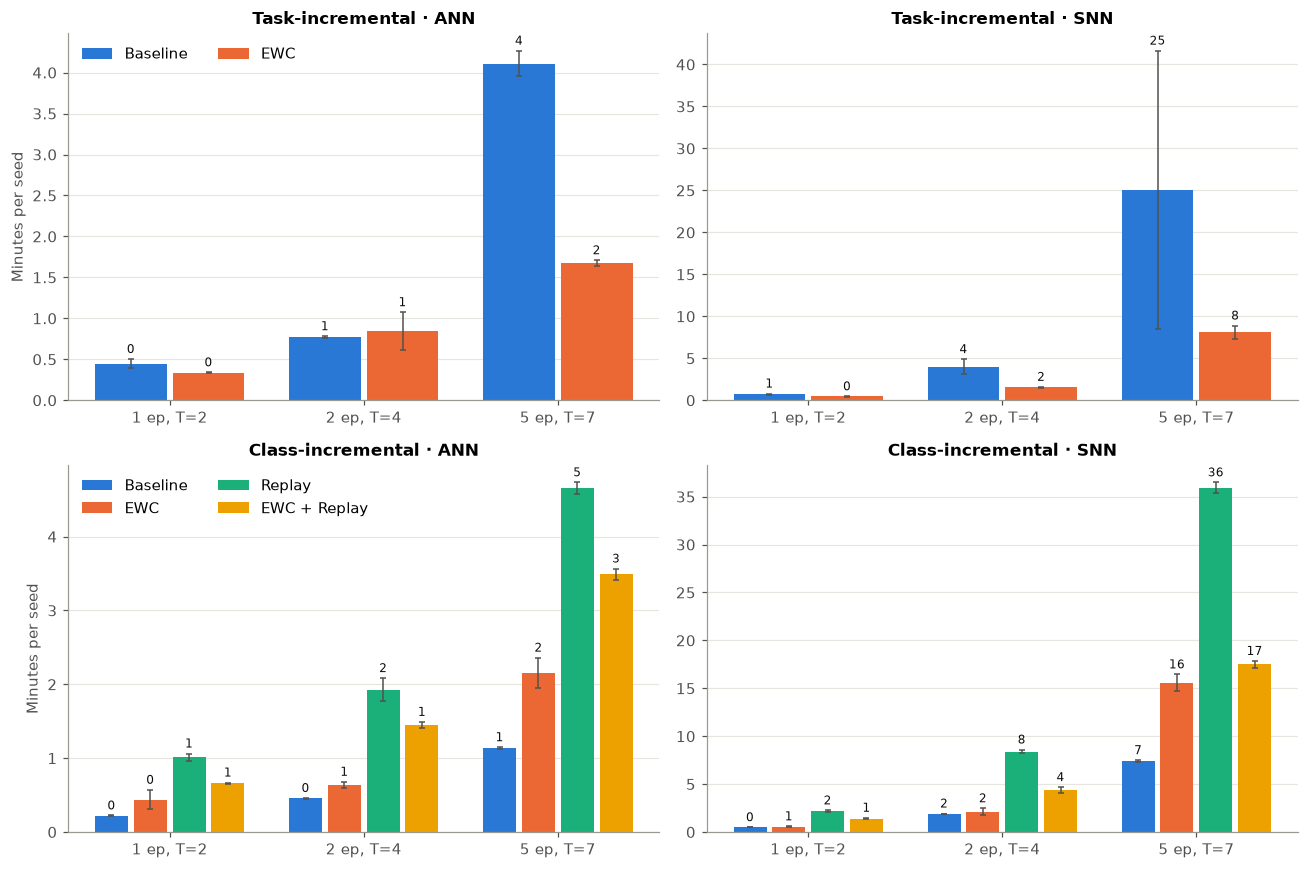

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (sc, methods) in enumerate(data.items()):
    for col, m in enumerate(("ann", "snn")):
        ax = axes[row, col]
        names = list(methods)
        grouped_bars(ax, COND_LABELS, [per_cond(methods[n], m, train_time) for n in names],
                     [METHOD_COLORS[n] for n in names], names, fmt="{:.0f}")
        ax.set_title(f"{SCENARIO_TITLE[sc]} · {MODEL_NAMES[m]}")
        if col == 0:
            ax.set_ylabel("Minutes per seed")
            ax.legend(loc="upper left", ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "ewc_training_time.png")
plt.show()